## Import Libraries

In [1]:
import os
import pandas as pd
from glob import glob
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SIZE = 224
BATCH_SIZE = 32
base_dir = "/kaggle/input/brain-cancer-mri-colorized-dataset/data"

# Step 1: Collect all image paths & labels (2 levels deep)
data = []
for cls in os.listdir(base_dir):  # brain_glioma, brain_menin, brain_tumor
    cls_path = os.path.join(base_dir, cls)
    if os.path.isdir(cls_path):
        for subfolder in os.listdir(cls_path):  # augmentation folders
            subfolder_path = os.path.join(cls_path, subfolder)
            if os.path.isdir(subfolder_path):
                for img in glob(os.path.join(subfolder_path, '*.*')):
                    data.append({"filepath": img, "label": cls})

df = pd.DataFrame(data)
print("Total images:", len(df))
print(df.head())

# Step 2: Split into train (70%), validation (20%), and test (10%)
train_val_df, test_df = train_test_split(df, test_size=0.1, stratify=df['label'], random_state=42)
train_df, val_df = train_test_split(train_val_df, test_size=0.2, stratify=train_val_df['label'], random_state=42)

# Step 3: Define ImageDataGenerator
datagen = ImageDataGenerator(rescale=1./255)

train_generator = datagen.flow_from_dataframe(
    train_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

validation_generator = datagen.flow_from_dataframe(
    val_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

test_generator = datagen.flow_from_dataframe(
    test_df,
    x_col='filepath',
    y_col='label',
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

# Optional: Check distribution
print("Train class distribution:\n", train_df['label'].value_counts())
print("Validation class distribution:\n", val_df['label'].value_counts())
print("Test class distribution:\n", test_df['label'].value_counts())


2025-08-10 16:03:39.191271: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1754841819.370601      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1754841819.424799      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Total images: 78728
                                            filepath        label
0  /kaggle/input/brain-cancer-mri-colorized-datas...  brain_tumor
1  /kaggle/input/brain-cancer-mri-colorized-datas...  brain_tumor
2  /kaggle/input/brain-cancer-mri-colorized-datas...  brain_tumor
3  /kaggle/input/brain-cancer-mri-colorized-datas...  brain_tumor
4  /kaggle/input/brain-cancer-mri-colorized-datas...  brain_tumor
Found 56684 validated image filenames belonging to 3 classes.
Found 14171 validated image filenames belonging to 3 classes.
Found 7873 validated image filenames belonging to 3 classes.
Train class distribution:
 label
brain_tumor     19169
brain_menin     18758
brain_glioma    18757
Name: count, dtype: int64
Validation class distribution:
 label
brain_tumor     4792
brain_glioma    4690
brain_menin     4689
Name: count, dtype: int64
Test class distribution:
 label
brain_tumor     2663
brain_menin     2605
brain_glioma    2605
Name: count, dtype: int64


In [2]:
import os
import random
import shutil

# Output folder to save samples
output_folder = "/kaggle/working/sample_images"
os.makedirs(output_folder, exist_ok=True)

# Loop through each class and pick one random image
for cls in df['label'].unique():
    sample_row = df[df['label'] == cls].sample(1, random_state=42)
    src = sample_row['filepath'].values[0]
    dst = os.path.join(output_folder, f"{cls}_{os.path.basename(src)}")
    shutil.copy(src, dst)

print(f"✅ One sample from each class saved to: {output_folder}")


✅ One sample from each class saved to: /kaggle/working/sample_images


## VGG16

In [3]:


from tensorflow.keras.applications import VGG16
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling2D, BatchNormalization, Dropout, Dense

# Load pre-trained VGG16 model without top classification layers
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False  # Freeze the convolutional base

# Define the model architecture
model = models.Sequential([
    base_model,
    GlobalMaxPooling2D(),                        # Replace Flatten with GlobalMaxPooling
    Dense(256, activation='relu'),
    BatchNormalization(),                        # Add Batch Normalization
    Dropout(0.5),
    Dense(len(train_generator.class_indices), activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Train the model
model.fit(train_generator,
          epochs=10,
          validation_data=validation_generator)

# Evaluate on the validation set
loss, accuracy = model.evaluate(validation_generator)
print(f"Validation Accuracy: {accuracy:.4f}")


I0000 00:00:1754841957.266321      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10


I0000 00:00:1754841962.449994      59 service.cc:148] XLA service 0x79e294010210 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1754841962.450721      59 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1754841962.904465      59 cuda_dnn.cc:529] Loaded cuDNN version 90300


   2/1772 ━━━━━━━━━━━━━━━━━━━━ 2:11 74ms/step - accuracy: 0.4297 - loss: 1.5373  

I0000 00:00:1754841971.331706      59 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1772/1772 ━━━━━━━━━━━━━━━━━━━━ 496s 274ms/step - accuracy: 0.7551 - loss: 0.6109 - val_accuracy: 0.8289 - val_loss: 0.4006
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 235s 133ms/step - accuracy: 0.8146 - loss: 0.4455 - val_accuracy: 0.8319 - val_loss: 0.4039
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 223s 126ms/step - accuracy: 0.8208 - loss: 0.4292 - val_accuracy: 0.8378 - val_loss: 0.3820
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 211s 119ms/step - accuracy: 0.8232 - loss: 0.4258 - val_accuracy: 0.8220 - val_loss: 0.4485
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 227s 128ms/step - accuracy: 0.8273 - loss: 0.4207 - val_accuracy: 0.7982 - val_loss: 0.4580
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 223s 126ms/step - accuracy: 0.8266 - loss: 0.4166 - val_accuracy: 0.8370 - val_loss: 0.3640
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 206s 116ms/step - accuracy: 0.8354 - loss: 0.4051 - val_accuracy: 0.8309 - val_loss: 0.3956
Epoch 8/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 212s 120ms/step - accuracy: 0.8

In [4]:
loss, accuracy = model.evaluate(test_generator)
print(f"Validation Accuracy: {accuracy:.4f}")

247/247 ━━━━━━━━━━━━━━━━━━━━ 55s 223ms/step - accuracy: 0.8614 - loss: 0.3382
Validation Accuracy: 0.8607


## EfficientNetB0

In [5]:
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling2D, BatchNormalization, Dropout, Dense

base_model = EfficientNetB0(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

modeleff = models.Sequential([
    base_model,
    GlobalMaxPooling2D(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(len(train_generator.class_indices), activation='softmax')
])

modeleff.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

modeleff.fit(train_generator,
          epochs=10,
          validation_data=validation_generator)

loss, accuracy = modeleff.evaluate(test_generator)
print(f"Validation Accuracy (EfficientNetB0): {accuracy:.4f}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 251s 128ms/step - accuracy: 0.3577 - loss: 1.1928 - val_accuracy: 0.3310 - val_loss: 1.1809
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 207s 117ms/step - accuracy: 0.4041 - loss: 1.0806 - val_accuracy: 0.3753 - val_loss: 1.0818
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 213s 120ms/step - accuracy: 0.4249 - loss: 1.0667 - val_accuracy: 0.3408 - val_loss: 1.2158
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 255s 144ms/step - accuracy: 0.4396 - loss: 1.0554 - val_accuracy: 0.3311 - val_loss: 1.5658
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 223s 126ms/step - accuracy: 0.4462 - loss: 1.0503 - val_accuracy: 0.3310 - val_loss: 1.7523
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 204s 115ms/step - accuracy: 0.4478 - loss: 1.0434 - val_accuracy: 0.4405 - val_loss: 1.0413
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 211s 119ms/step - accuracy: 0.4507 - loss: 1.0434 - val_accuracy: 0.3382 - val_loss: 1.9514
Epoch 8/10


## MobileNetV2

In [6]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling2D, BatchNormalization, Dropout, Dense

base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

modelmn = models.Sequential([
    base_model,
    GlobalMaxPooling2D(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(len(train_generator.class_indices), activation='softmax')
])

modelmn.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

modelmn.fit(train_generator,
          epochs=10,
          validation_data=validation_generator)

loss, accuracy = modelmn.evaluate(test_generator)
print(f"Validation Accuracy (MobileNetV2): {accuracy:.4f}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 218s 117ms/step - accuracy: 0.7992 - loss: 0.5341 - val_accuracy: 0.8673 - val_loss: 0.3253
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 216s 122ms/step - accuracy: 0.8651 - loss: 0.3443 - val_accuracy: 0.8543 - val_loss: 0.3595
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 226s 128ms/step - accuracy: 0.8714 - loss: 0.3272 - val_accuracy: 0.8783 - val_loss: 0.2969
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 224s 126ms/step - accuracy: 0.8734 - loss: 0.3212 - val_accuracy: 0.8669 - val_loss: 0.3179
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 207s 117ms/step - accuracy: 0.8764 - loss: 0.3165 - val_accuracy: 0.8851 - val_loss: 0.2874
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 342s 193ms/step - accuracy: 0.8788 - loss: 0.3110 - val_accuracy: 0.8790 - val_loss: 0.3017
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 195s 110ms/step - accuracy: 0.8774 - loss: 0.3153 - val_accuracy: 0.8898 - val_loss: 0.2671
Epoch 8/10
17

## ResNet50

In [7]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalMaxPooling2D, BatchNormalization, Dropout, Dense

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
base_model.trainable = False

modelrn = models.Sequential([
    base_model,
    GlobalMaxPooling2D(),
    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.5),
    Dense(len(train_generator.class_indices), activation='softmax')
])

modelrn.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

modelrn.fit(train_generator,
          epochs=10,
          validation_data=validation_generator)

loss, accuracy = modelrn.evaluate(test_generator)
print(f"Validation Accuracy (ResNet50): {accuracy:.4f}")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 229s 121ms/step - accuracy: 0.6115 - loss: 0.8709 - val_accuracy: 0.5648 - val_loss: 0.9965
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 233s 131ms/step - accuracy: 0.6912 - loss: 0.6822 - val_accuracy: 0.4889 - val_loss: 2.5205
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 203s 114ms/step - accuracy: 0.7084 - loss: 0.6561 - val_accuracy: 0.7172 - val_loss: 0.6523
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 245s 138ms/step - accuracy: 0.7135 - loss: 0.6432 - val_accuracy: 0.5240 - val_loss: 1.0008
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 206s 116ms/step - accuracy: 0.7201 - loss: 0.6351 - val_accuracy: 0.6959 - val_loss: 0.6620
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 208s 117ms/step - accuracy: 0.7225 - loss: 0.6311 - val_accuracy: 0.7052 - val_loss: 0.6391
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 291s 164ms/step - accuracy: 0.7252 - loss: 0.6253 - val_accuracy: 0.6559 - val_loss: 0.7731
Epoch 8/10


## Scratch Model

In [8]:
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam

# Define image size and number of classes
IMG_SIZE = 224
NUM_CLASSES = len(train_generator.class_indices)

# Custom CNN model
modelscr = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    # First Convolutional Block
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Second Convolutional Block
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Third Convolutional Block
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Fourth Convolutional Block
    layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Flatten and Dense Layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.5),
    layers.Dense(len(train_generator.class_indices), activation='softmax')
])

# Compile the model
modelscr.compile(optimizer=Adam(learning_rate=1e-4),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

# Print model summary
modelscr.summary()

# Train the model
modelscr.fit(train_generator,
          epochs=10,
          validation_data=validation_generator)

# Evaluate on the validation set
loss, accuracy = modelscr.evaluate(test_generator)
print(f"Validation Accuracy (Scratch Model): {accuracy:.4f}")

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 32)        │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 224, 224, 32)        │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 32)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 112, 112, 64)        │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 112, 112, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 56, 56, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_6                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_7                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_8                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_4 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 3)                   │             771 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 457,923 (1.75 MB)

 Trainable params: 456,451 (1.74 MB)

 Non-trainable params: 1,472 (5.75 KB)

Epoch 1/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 223s 120ms/step - accuracy: 0.6208 - loss: 0.9940 - val_accuracy: 0.7388 - val_loss: 0.6294
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 199s 112ms/step - accuracy: 0.7374 - loss: 0.6602 - val_accuracy: 0.8110 - val_loss: 0.4587
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 194s 109ms/step - accuracy: 0.7920 - loss: 0.5077 - val_accuracy: 0.8239 - val_loss: 0.3904
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 217s 123ms/step - accuracy: 0.8396 - loss: 0.3847 - val_accuracy: 0.8844 - val_loss: 0.2835
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 203s 114ms/step - accuracy: 0.8681 - loss: 0.3144 - val_accuracy: 0.8755 - val_loss: 0.2877
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 263s 149ms/step - accuracy: 0.8911 - loss: 0.2627 - val_accuracy: 0.8977 - val_loss: 0.2414
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 317s 179ms/step - accuracy: 0.9036 - loss: 0.2304 - val_accuracy: 0.9040 - val_loss: 0.2240
Epoch 8/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 360s 203ms/step - ac

VGG Mobile combined

In [9]:
from tensorflow.keras.applications import VGG16, MobileNetV2
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, GlobalMaxPooling2D, Dense, Dropout, BatchNormalization, Concatenate

input_shape = (IMG_SIZE, IMG_SIZE, 3)
input_layer = Input(shape=input_shape)

# --- Model 1: VGG16 branch ---
vgg_base = VGG16(weights='imagenet', include_top=False, input_tensor=input_layer)
vgg_base.trainable = False
x = GlobalMaxPooling2D()(vgg_base.output)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)

# --- Model 2: MobileNetV2 branch ---
mobilenet_base = MobileNetV2(weights='imagenet', include_top=False, input_tensor=input_layer)
mobilenet_base.trainable = False
y = GlobalMaxPooling2D()(mobilenet_base.output)
y = Dense(256, activation='relu')(y)
y = BatchNormalization()(y)
y = Dropout(0.5)(y)

# --- Merge both outputs ---
merged = Concatenate()([x, y])

# --- Final output layer ---
output = Dense(len(train_generator.class_indices), activation='softmax')(merged)

# Define the final model
fusion_model = Model(inputs=input_layer, outputs=output)


/tmp/ipykernel_19/940479714.py:17: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_base = MobileNetV2(weights='imagenet', include_top=False, input_tensor=input_layer)


In [10]:
fusion_model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


In [11]:
history = fusion_model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)


Epoch 1/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 242s 129ms/step - accuracy: 0.8174 - loss: 0.4877 - val_accuracy: 0.8562 - val_loss: 0.3837
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 220s 124ms/step - accuracy: 0.8834 - loss: 0.3014 - val_accuracy: 0.8937 - val_loss: 0.2618
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 253s 143ms/step - accuracy: 0.8914 - loss: 0.2799 - val_accuracy: 0.9033 - val_loss: 0.2433
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 228s 129ms/step - accuracy: 0.8967 - loss: 0.2658 - val_accuracy: 0.9004 - val_loss: 0.2541
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 210s 118ms/step - accuracy: 0.8979 - loss: 0.2608 - val_accuracy: 0.9101 - val_loss: 0.2285
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 214s 121ms/step - accuracy: 0.9016 - loss: 0.2527 - val_accuracy: 0.9157 - val_loss: 0.2191
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 238s 134ms/step - accuracy: 0.9067 - loss: 0.2409 - val_accuracy: 0.9043 - val_loss: 0.2352
Epoch 8/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 212s 119ms/step - ac

In [12]:

loss, accuracy = fusion_model.evaluate(test_generator)
print(f"Validation Accuracy (Fusion): {accuracy:.4f}")


247/247 ━━━━━━━━━━━━━━━━━━━━ 35s 141ms/step - accuracy: 0.9113 - loss: 0.2165
Validation Accuracy (Fusion): 0.9093


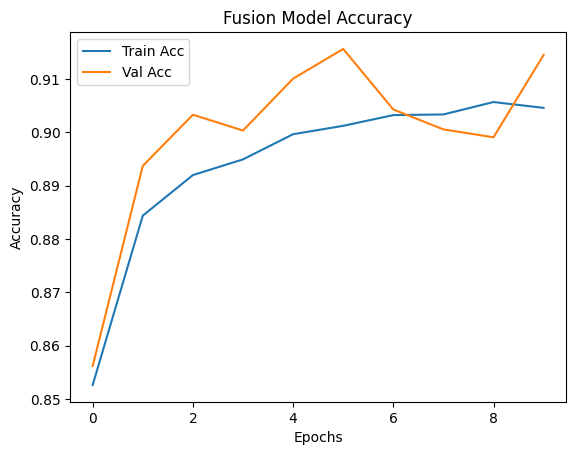

In [13]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Fusion Model Accuracy')
plt.legend()
plt.show()


After unfreezing the models

In [14]:
# Unfreeze last few layers
vgg_base.trainable = True
x = GlobalMaxPooling2D()(vgg_base.output)
x = Dense(256, activation='relu')(x)
x = BatchNormalization()(x)
x = Dropout(0.5)(x)
mobilenet_base.trainable = True
y = GlobalMaxPooling2D()(mobilenet_base.output)
y = Dense(256, activation='relu')(y)
y = BatchNormalization()(y)
y = Dropout(0.5)(y)

# --- Merge both outputs ---
merged = Concatenate()([x, y])

# --- Final output layer ---
output = Dense(len(train_generator.class_indices), activation='softmax')(merged)

# Define the final model
fusion_model2 = Model(inputs=input_layer, outputs=output)

# Re-compile with a lower learning rate
from tensorflow.keras.optimizers import Adam
fusion_model2.compile(
    optimizer=Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Continue training
history=fusion_model2.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)


Epoch 1/10


E0000 00:00:1754856425.220260      59 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1754856425.417854      59 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 405/1772 ━━━━━━━━━━━━━━━━━━━━ 6:37 291ms/step - accuracy: 0.5840 - loss: 1.0665

E0000 00:00:1754856575.598382      60 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1754856575.794519      60 gpu_timer.cc:82] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1772/1772 ━━━━━━━━━━━━━━━━━━━━ 703s 352ms/step - accuracy: 0.7341 - loss: 0.6886 - val_accuracy: 0.9177 - val_loss: 0.2051
Epoch 2/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 571s 322ms/step - accuracy: 0.9050 - loss: 0.2404 - val_accuracy: 0.9416 - val_loss: 0.1387
Epoch 3/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 595s 336ms/step - accuracy: 0.9300 - loss: 0.1811 - val_accuracy: 0.9489 - val_loss: 0.1213
Epoch 4/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 560s 316ms/step - accuracy: 0.9439 - loss: 0.1477 - val_accuracy: 0.9574 - val_loss: 0.1084
Epoch 5/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 562s 317ms/step - accuracy: 0.9525 - loss: 0.1222 - val_accuracy: 0.9580 - val_loss: 0.1107
Epoch 6/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 556s 314ms/step - accuracy: 0.9619 - loss: 0.1025 - val_accuracy: 0.9659 - val_loss: 0.0836
Epoch 7/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 554s 313ms/step - accuracy: 0.9660 - loss: 0.0894 - val_accuracy: 0.9658 - val_loss: 0.0882
Epoch 8/10
1772/1772 ━━━━━━━━━━━━━━━━━━━━ 558s 315ms/step - accuracy: 0.9

In [15]:
loss, accuracy = fusion_model2.evaluate(test_generator)
print(f"Test Accuracy: {accuracy:.4f}")


247/247 ━━━━━━━━━━━━━━━━━━━━ 33s 134ms/step - accuracy: 0.9666 - loss: 0.0858
Test Accuracy: 0.9652


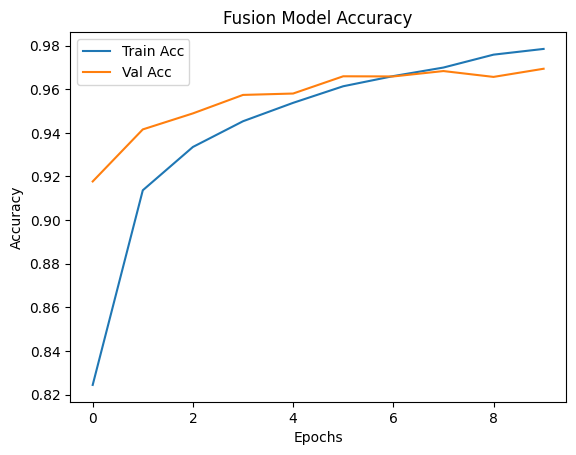

In [16]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.title('Fusion Model Accuracy')
plt.legend()

# Save the plot as PNG in Kaggle working directory
plot_path = "/kaggle/working/_trainable_fusion_model2_accuracy.png"
plt.savefig(plot_path, dpi=300, bbox_inches='tight')

plt.show()


Confusion matrix

247/247 ━━━━━━━━━━━━━━━━━━━━ 31s 108ms/step


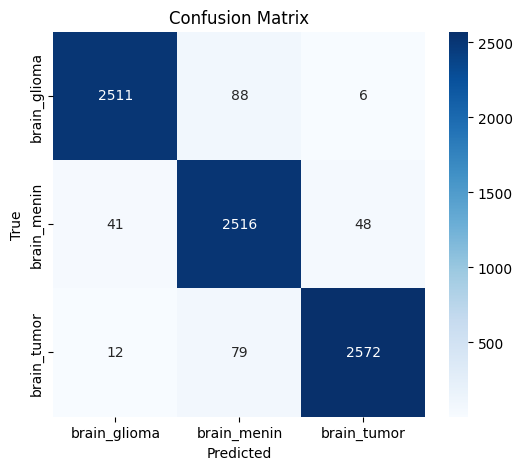

              precision    recall  f1-score   support

brain_glioma       0.98      0.96      0.97      2605
 brain_menin       0.94      0.97      0.95      2605
 brain_tumor       0.98      0.97      0.97      2663

    accuracy                           0.97      7873
   macro avg       0.97      0.97      0.97      7873
weighted avg       0.97      0.97      0.97      7873



In [17]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Get true labels
true_labels = test_generator.classes

# Predict probabilities
y_pred_probs = fusion_model2.predict(test_generator)


y_pred = np.argmax(y_pred_probs, axis=1)
y_true = test_generator.classes

# Class names
class_names = list(test_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

# Plot Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')

# Save in Kaggle working directory
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=300, bbox_inches='tight')
plt.show()
print(classification_report(true_labels, y_pred, target_names=class_names))


Gradcam Output

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_632']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


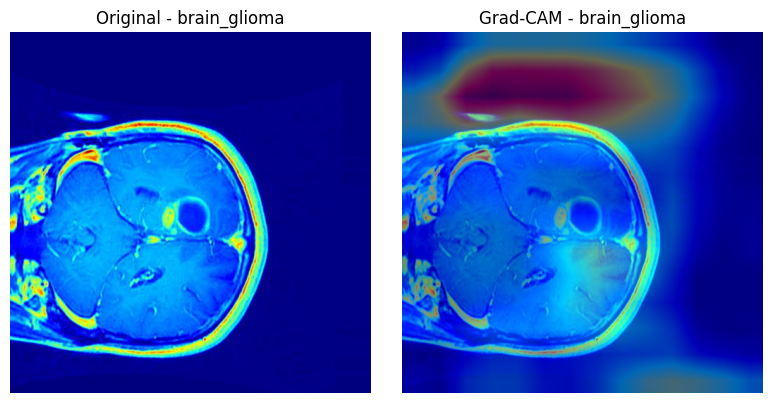

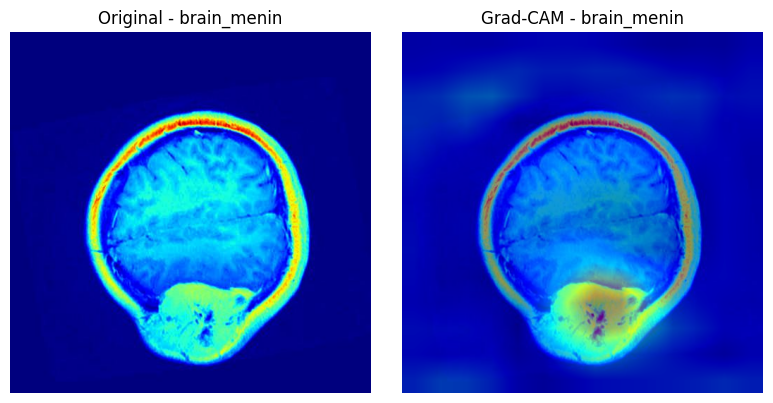

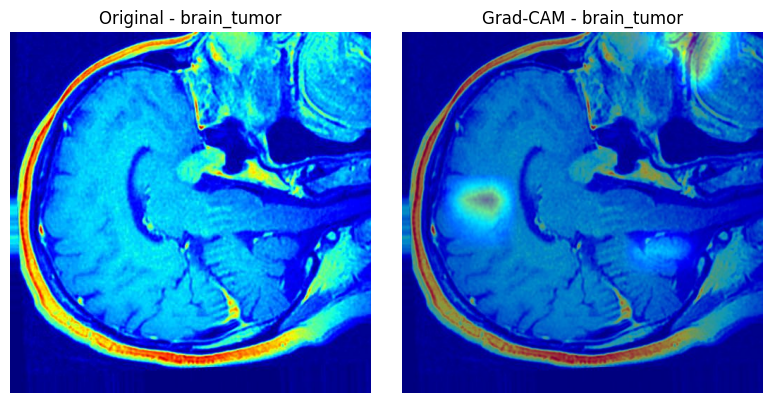

All side-by-side Grad-CAM images saved to: /kaggle/working/gradcams


In [18]:
import tensorflow as tf
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
from tensorflow.keras.preprocessing import image

def get_gradcam(model, img_array, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        loss = predictions[:, pred_index]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)
    heatmap = np.maximum(heatmap, 0)
    max_val = np.max(heatmap)
    if max_val != 0:
        heatmap /= max_val  # normalize
    return heatmap

# Class names from generator
class_names = list(test_generator.class_indices.keys())

# Pick one sample from each class
sample_images = []
for cls in class_names:
    for path, label in zip(test_generator.filepaths, test_generator.classes):
        if class_names[label] == cls:
            sample_images.append((path, cls))
            break  # take only first match

# Output directory
output_dir = "/kaggle/working/gradcams"
os.makedirs(output_dir, exist_ok=True)

# Generate Grad-CAM for each sample
for img_path, cls in sample_images:
    # Load and preprocess for model
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0

    # Get Grad-CAM heatmap
    heatmap = get_gradcam(fusion_model2, img_array, last_conv_layer_name="block5_conv3")

    # Read original for overlay
    img_orig = cv2.imread(img_path)
    heatmap_resized = cv2.resize(heatmap, (img_orig.shape[1], img_orig.shape[0]))
    heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    superimposed_img = cv2.addWeighted(img_orig, 0.6, heatmap_color, 0.4, 0)

    # Save combined side-by-side image
    combined_img = np.hstack((img_orig, superimposed_img))
    save_path = os.path.join(output_dir, f"gradcam_side_by_side_{cls}.jpg")
    cv2.imwrite(save_path, combined_img)

    # Show side-by-side
    plt.figure(figsize=(8, 4))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB))
    plt.title(f"Original - {cls}")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(superimposed_img, cv2.COLOR_BGR2RGB))
    plt.title(f"Grad-CAM - {cls}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

print(f"All side-by-side Grad-CAM images saved to: {output_dir}")


LIME

In [19]:
import shap
import lime
import lime.lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np
import os
from tensorflow.keras.preprocessing import image

# Create folder to save outputs
os.makedirs("/kaggle/working/explainability", exist_ok=True)

# 1️⃣ Pick 1 sample from each class
class_samples = {}
for img_path, label in zip(test_generator.filepaths, test_generator.labels):
    label_name = list(test_generator.class_indices.keys())[label]
    if label_name not in class_samples:
        class_samples[label_name] = img_path
    if len(class_samples) == len(test_generator.class_indices):
        break

# 2️⃣ SHAP setup - using Image masker
background = np.array([
    image.img_to_array(image.load_img(fp, target_size=(224, 224))) / 255.0
    for fp in test_generator.filepaths[:50]
])
masker = shap.maskers.Image("blur(128,128)", (224, 224, 3))
shap_explainer = shap.Explainer(fusion_model2, masker, output_names=list(test_generator.class_indices.keys()))

# 3️⃣ LIME setup
lime_explainer = lime.lime_image.LimeImageExplainer()

# Loop over each class
for class_name, img_path in class_samples.items():
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_batch = np.expand_dims(img_array, axis=0)

    # ===== SHAP =====
    shap_values = shap_explainer(img_batch)
    plt.figure()
    shap.image_plot(shap_values, show=False)
    shap_filename = f"/kaggle/working/explainability/shap_{class_name}.png"
    plt.savefig(shap_filename, bbox_inches='tight')
    plt.close()

    # ===== LIME =====
    def predict_fn(images):
        return fusion_model2.predict(np.array(images))

    lime_exp = lime_explainer.explain_instance(
        img_array.astype('double'),
        predict_fn,
        top_labels=3,
        hide_color=0,
        num_samples=1000
    )
    temp, mask = lime_exp.get_image_and_mask(
        lime_exp.top_labels[0],
        positive_only=True,
        num_features=10,
        hide_rest=False
    )
    plt.figure()
    plt.imshow(mark_boundaries(temp / 255.0, mask))
    plt.axis('off')
    lime_filename = f"/kaggle/working/explainability/lime_{class_name}.png"
    plt.savefig(lime_filename, bbox_inches='tight')
    plt.close()

print("✅ SHAP & LIME saved in /kaggle/working/explainability/")


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:13, 13.76s/it]               


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━

  0%|          | 0/498 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

... (3 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

Cohen's kappa

In [20]:
import numpy as np
import os
from sklearn.metrics import cohen_kappa_score, classification_report, confusion_matrix

# 1️⃣ Make sure statistics directory exists
os.makedirs("/kaggle/working/statistics", exist_ok=True)

# 2️⃣ Get predictions on test data
Y_pred_probs = fusion_model.predict(test_generator)
Y_pred = np.argmax(Y_pred_probs, axis=1)  # predicted class indices

# 3️⃣ Get true labels
Y_true = test_generator.classes  # already class indices

# 4️⃣ Class names
class_names = list(test_generator.class_indices.keys())

# ===== Cohen's Kappa =====
kappa = cohen_kappa_score(Y_true, Y_pred)
print(f"Cohen's Kappa: {kappa:.4f}")
with open("/kaggle/working/statistics/kappa_score.txt", "w") as f:
    f.write(f"Cohen's Kappa: {kappa:.4f}\n")

# ===== Classification Report =====
report = classification_report(Y_true, Y_pred, target_names=class_names)
print(report)
with open("/kaggle/working/statistics/classification_report.txt", "w") as f:
    f.write(report)

# ===== Confusion Matrix =====
cm = confusion_matrix(Y_true, Y_pred)
np.savetxt("/kaggle/working/statistics/confusion_matrix.csv", cm, delimiter=",", fmt="%d")


247/247 ━━━━━━━━━━━━━━━━━━━━ 31s 109ms/step
Cohen's Kappa: 0.5535
              precision    recall  f1-score   support

brain_glioma       0.78      0.64      0.70      2605
 brain_menin       0.67      0.82      0.74      2605
 brain_tumor       0.68      0.65      0.66      2663

    accuracy                           0.70      7873
   macro avg       0.71      0.70      0.70      7873
weighted avg       0.71      0.70      0.70      7873



McNemar's Test

In [21]:
from statsmodels.stats.contingency_tables import mcnemar
import numpy as np

# Example: baseline predictions (replace with another model's preds if available)
baseline_pred = np.random.choice(len(train_generator.class_indices), size=len(Y_true))

# Create contingency table
correct_model = (Y_pred == Y_true)
correct_baseline = (baseline_pred == Y_true)

# 2x2 table: [ [both_correct, baseline_correct_only], [model_correct_only, both_wrong] ]
table = [
    [np.sum(correct_model & correct_baseline), np.sum(~correct_model & correct_baseline)],
    [np.sum(correct_model & ~correct_baseline), np.sum(~correct_model & ~correct_baseline)]
]

# Perform McNemar's test
result = mcnemar(table, exact=False)
print(f"McNemar’s Test Statistic: {result.statistic:.4f}, p-value: {result.pvalue:.4f}")

# Save results
with open("/kaggle/working/statistics/mcnemar_test.txt", "w") as f:
    f.write(f"McNemar’s Test Statistic: {result.statistic:.4f}, p-value: {result.pvalue:.4f}")


McNemar’s Test Statistic: 1964.9842, p-value: 0.0000


Summary report

In [22]:
summary_path = "/kaggle/working/statistics/model_summary.txt"
with open(summary_path, "w") as f:
    f.write("MODEL STATISTICAL ANALYSIS\n")
    f.write("="*40 + "\n")
    f.write(f"Cohen's Kappa: {kappa:.4f}\n")
    f.write(f"McNemar’s Test Statistic: {result.statistic:.4f}, p-value: {result.pvalue:.4f}\n\n")
    f.write("Classification Report:\n")
    f.write(classification_report(Y_true, Y_pred, target_names=class_labels))


NameError: name 'class_labels' is not defined